In [248]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import TransformerMixin
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, FunctionTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, StratifiedKFold, RandomizedSearchCV
from sklearn.neighbors import KNeighborsClassifier
import seaborn as sns

In [249]:
df = pd.read_csv("train.csv")
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


### EDA

In [250]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


In [251]:
df[['group', 'num_in_group']] = df['PassengerId'].str.split('_', expand=True)
df[['first_name', 'last_name']] = df['Name'].str.split(" ", expand=True)
df[['c_deck', 'c_num', 'c_side']] = df['Cabin'].str.split("/", expand=True)

In [252]:
df['group_size'] = df.groupby("group")['PassengerId'].transform('count')

In [253]:
df.groupby("group")[['HomePlanet']].nunique()\
    .sort_values(by=['HomePlanet'], ascending=False)

,HomePlanet
group,
9280,1
0001,1
0002,1
0003,1
0004,1
...,...
0303,0
0242,0
0251,0


In [254]:
df.groupby("group")[['last_name']].nunique().sort_values(by=['last_name'], ascending=False)

,last_name
group,
6302,4
0984,3
4005,3
3283,3
3862,3
...,...
0372,0
0190,0
0136,0


In [255]:
df.groupby(["HomePlanet", "Destination"]).count()

PassengerId  CryoSleep  Cabin   Age   VIP  \
HomePlanet Destination                                                
Earth      55 Cancri e            690        677    676   682   668   
           PSO J318.5-22          712        695    696   699   693   
           TRAPPIST-1e           3101       3018   3038  3034  3030   
Europa     55 Cancri e            886        861    854   862   870   
           PSO J318.5-22           19         19     18    19    19   
           TRAPPIST-1e           1189       1158   1161  1168  1163   
Mars       55 Cancri e            193        188    191   191   189   
           PSO J318.5-22           49         47     48    48    47   
           TRAPPIST-1e           1475       1440   1443  1437  1438   

                          RoomService  FoodCourt  ShoppingMall   Spa  VRDeck  \
HomePlanet Destination                                                         
Earth      55 Cancri e            680        671           673   676     673   
           PSO J318.5-22          694        699           694   697     701   
           TRAPPIST-1e           3027       3038          3028  3033    3019   
Europa     55 Cancri e            873        870           866   864     867   
           PSO J318.5-22           18         18            19    19      19   
           TRAPPIST-1e           1168       1162          1156  1167    1172   
Mars       55 Cancri e            188        191           184   190     189   
           PSO J318.5-22           47         48            49    48      48   
           TRAPPIST-1e           1447       1442          1449  1443    1441   

                          Name  Transported  group  num_in_group  first_name  \
HomePlanet Destination                                                         
Earth      55 Cancri e     672          690    690           690         672   
           PSO J318.5-22   695          712    712           712         695   
           TRAPPIST-1e    3032         3101   3101          3101        3032   
Europa     55 Cancri e     869          886    886           886         869   
           PSO J318.5-22    19           19     19            19          19   
           TRAPPIST-1e    1160         1189   1189          1189        1160   
Mars       55 Cancri e     186          193    193           193         186   
           PSO J318.5-22    49           49     49            49          49   
           TRAPPIST-1e    1443         1475   1475          1475        1443   

                          last_name  c_deck  c_num  c_side  group_size  
HomePlanet Destination                                                  
Earth      55 Cancri e          672     676    676     676         690  
           PSO J318.5-22        695     696    696     696         712  
           TRAPPIST-1e         3032    3038   3038    3038        3101  
Europa     55 Cancri e          869     854    854     854         886  
           PSO J318.5-22         19      18     18      18          19  
           TRAPPIST-1e         1160    1161   1161    1161        1189  
Mars       55 Cancri e          186     191    191     191         193  
           PSO J318.5-22         49      48     48      48          49  
           TRAPPIST-1e         1443    1443   1443    1443        1475

In [256]:
# 7   RoomService   8512 non-null   float64
#  8   FoodCourt     8510 non-null   float64
#  9   ShoppingMall  8485 non-null   float64
#  10  Spa           8510 non-null   float64
#  11  VRDeck        8505 non-null   float64
# df.loc[:, ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']] = \
#     df[['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].fillna(0)
df['total_spent'] = df.loc[:, ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']].sum(axis=1)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 23 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  group         8693 non-null   str    
 15  num_in_group  8693 non-null   str    
 16  first_name    8493 non-null   str    
 17  last_name     8493 non-null   str    
 18  c_deck        8494 non-null   str    
 

In [257]:
df.groupby(["VIP", "CryoSleep"])[['total_spent']].agg(['mean', 'min', 'max', 'count'])

total_spent                    
                        mean  min      max count
VIP   CryoSleep                                 
False False      2160.761812  0.0  35987.0  5143
      True          0.000000  0.0      0.0  2941
True  False      4866.485714  0.0  31076.0   175
      True          0.000000  0.0      0.0    21

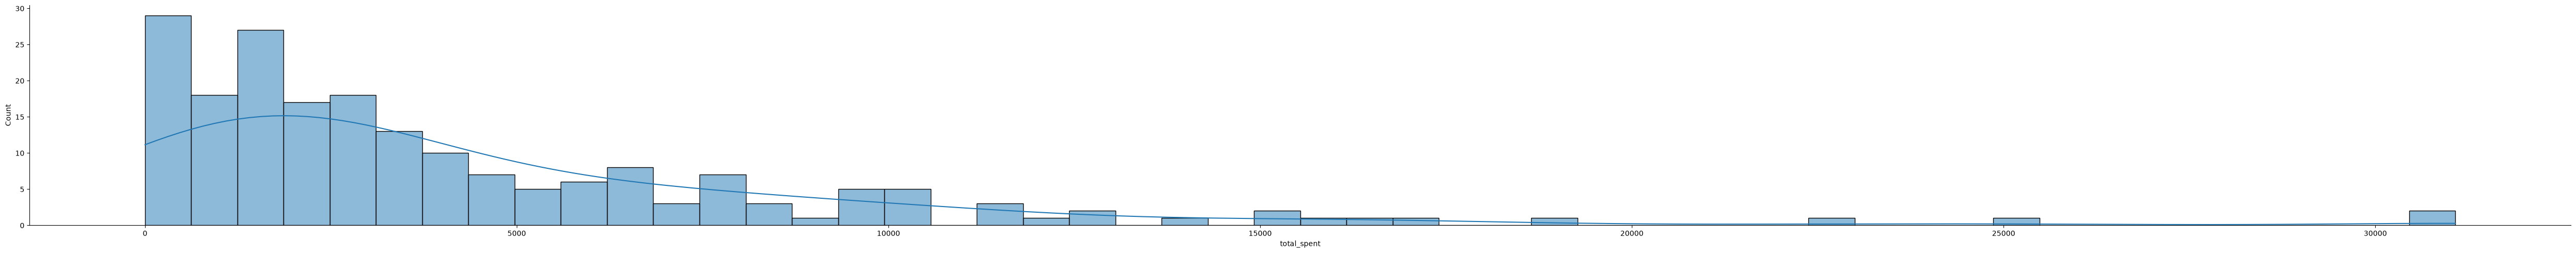

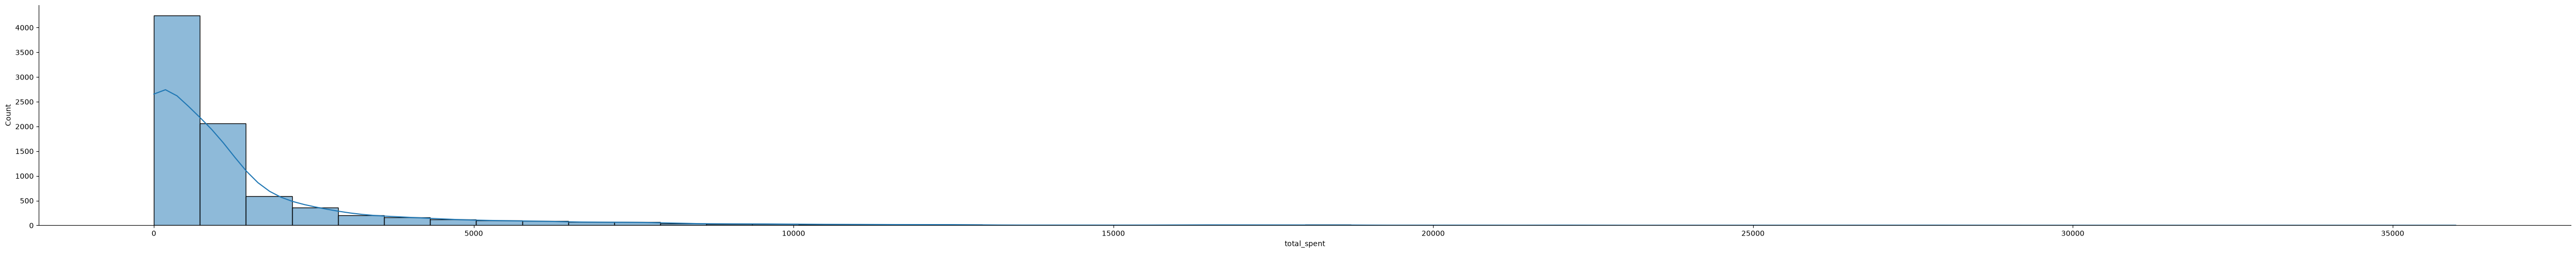

In [258]:
sns.displot(data=df[df['VIP']==True], x='total_spent', aspect=10, kde=True, bins=50);
plt.show()
sns.displot(data=df[df['VIP']==False], x='total_spent', aspect=10, kde=True, bins=50);
plt.show()

In [259]:
df[df['CryoSleep']&df['VIP']][['PassengerId', 'CryoSleep', 'VIP']]

,PassengerId,CryoSleep,VIP
365,0402_01,True,True
589,0612_01,True,True
1849,1976_03,True,True
2394,2572_02,True,True
2675,2866_01,True,True
3104,3349_01,True,True
4071,4348_01,True,True
4155,4441_01,True,True
4401,4668_02,True,True
4503,4786_01,True,True


In [260]:
df.groupby("CryoSleep")[['total_spent']].agg(['mean', 'min', 'max', 'count'])

total_spent                    
                  mean  min      max count
CryoSleep                                 
False      2248.299687  0.0  35987.0  5439
True          0.000000  0.0      0.0  3037

In [261]:
df['zero_spent'] = df['total_spent']==0
df.groupby(['CryoSleep', 'VIP', 'zero_spent']).size()

CryoSleep  VIP    zero_spent
False      False  False         4646
                  True           497
           True   False          168
                  True             7
True       False  True          2941
           True   True            21
dtype: int64

In [262]:
df[df['CryoSleep'].isna() & df['total_spent'] > 0][['PassengerId', 'CryoSleep', 'total_spent']].head(2)

,PassengerId,CryoSleep,total_spent
98,0105_01,NaN,703.0
104,0110_02,NaN,2018.0


In [263]:
df.loc[df['CryoSleep'].isna() & df['total_spent'] > 0, 'CryoSleep'] = False

In [264]:
df['CryoSleep'].value_counts()

CryoSleep
False    5558
True     3037
Name: count, dtype: int64

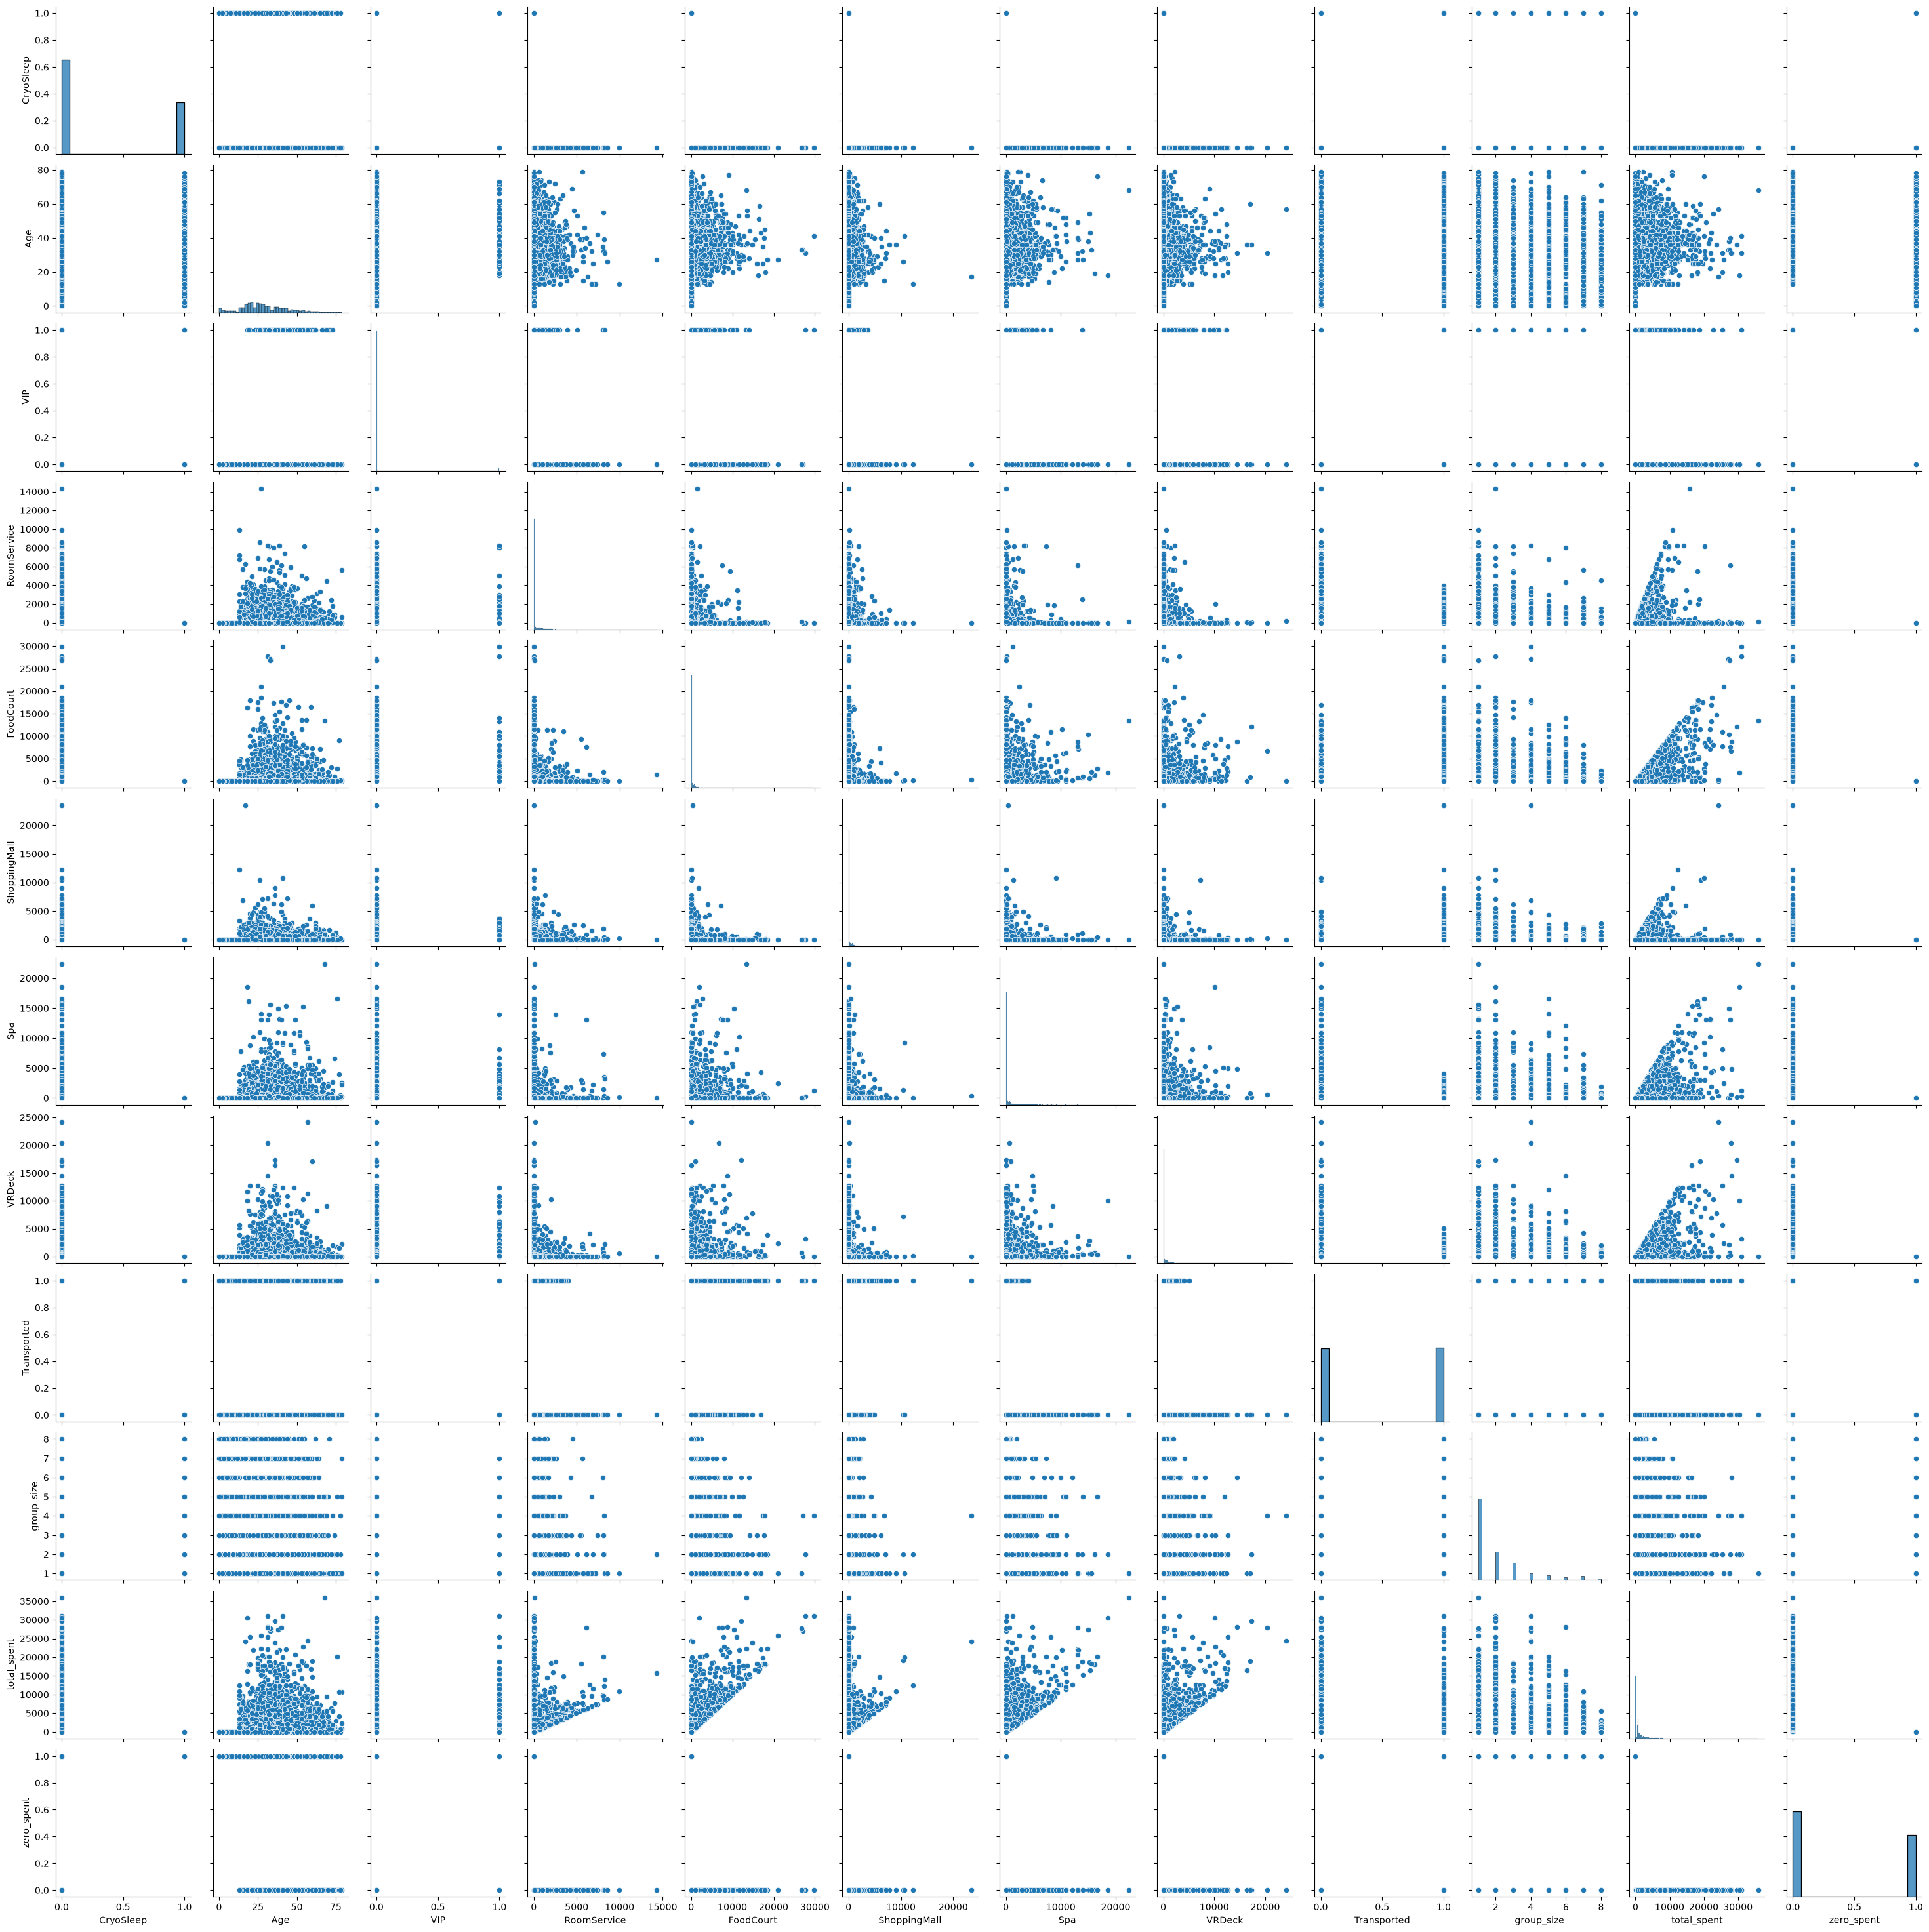

In [265]:
sns.pairplot(df)

In [266]:
df['HomePlanet'].isna().sum()

np.int64(201)

In [267]:
mask_no_home = df['HomePlanet'].isna()
df.loc[mask_no_home, 'HomePlanet'] = df.groupby('group')['HomePlanet']\
        .transform('first')[mask_no_home]

In [268]:
df['HomePlanet'].isna().sum()

np.int64(111)

In [269]:
gb_home = df.groupby('group')['HomePlanet'].nunique()
gb_home.value_counts()

HomePlanet
1    6107
0     110
Name: count, dtype: int64

In [270]:
gb_dst = df.groupby('group')['Destination'].nunique()
gb_dst.value_counts(normalize=True)

Destination
1    0.868104
2    0.107447
0    0.016567
3    0.007882
Name: proportion, dtype: float64

In [271]:
df[df['group']=='9280']

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,group,num_in_group,first_name,last_name,c_deck,c_num,c_side,group_size,total_spent,zero_spent
8691,9280_01,Europa,False,E/608/S,55 Cancri e,32.0,False,0.0,1049.0,0.0,...,9280,01,Celeon,Hontichre,E,608,S,2,4637.0,False
8692,9280_02,Europa,False,E/608/S,TRAPPIST-1e,44.0,False,126.0,4688.0,0.0,...,9280,02,Propsh,Hontichre,E,608,S,2,4826.0,False


In [272]:
gb_cryo = df.groupby('group')['CryoSleep'].nunique()
gb_cryo.value_counts(normalize=True)

CryoSleep
1    0.860705
2    0.133344
0    0.005951
Name: proportion, dtype: float64

In [273]:
df[df['Destination'].isna()]['group'].value_counts().sort_values(ascending=False)

group
0045    1
0138    1
0152    1
0382    1
0462    1
       ..
8956    1
9130    1
9195    1
9197    1
9226    1
Name: count, Length: 182, dtype: int64

In [274]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 24 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8582 non-null   str    
 2   CryoSleep     8595 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  group         8693 non-null   str    
 15  num_in_group  8693 non-null   str    
 16  first_name    8493 non-null   str    
 17  last_name     8493 non-null   str    
 18  c_deck        8494 non-null   str    
 

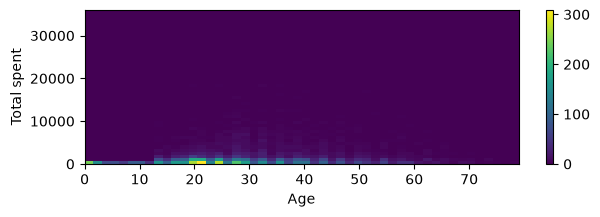

In [275]:
to_plt = df[['Age', 'total_spent']].dropna()
plt.figure(figsize=(7,2))
plt.hist2d(x=to_plt['Age'], y=to_plt['total_spent'], bins=50)
plt.xlabel('Age')
plt.ylabel('Total spent')
plt.colorbar()
plt.show()

In [276]:
df.groupby('group')[['c_deck', 'c_num', 'c_side']].nunique().sort_values('c_deck', ascending=False)

,c_deck,c_num,c_side
group,,,
3060,3,3,1
1709,3,3,1
0220,3,3,1
3236,3,3,1
0938,3,3,1
...,...,...,...
0327,0,0,0
0301,0,0,0
0239,0,0,0


In [277]:
df['c_side'].isna().sum()

np.int64(199)

In [278]:
mask_no_side = df['c_side'].isna()
df.loc[mask_no_side, 'c_side'] = df.groupby('group')['c_side']\
        .transform('first')[mask_no_side]

In [279]:
df['c_side'].isna().sum()

np.int64(99)

In [280]:
df[df['group_size']>1].groupby('group')[['c_deck']].nunique().value_counts()

c_deck
1         991
2         400
3          21
Name: count, dtype: int64

In [281]:
df[df['group']=='3060']

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,...,group,num_in_group,first_name,last_name,c_deck,c_num,c_side,group_size,total_spent,zero_spent
2831,3060_01,Mars,False,F/581/S,TRAPPIST-1e,13.0,False,760.0,2.0,2.0,...,3060,01,Rowl,Chman,F,581,S,3,764.0,False
2832,3060_02,Mars,False,D/98/S,TRAPPIST-1e,45.0,False,3309.0,0.0,10.0,...,3060,02,Duckes,Chman,D,98,S,3,3319.0,False
2833,3060_03,Mars,NaN,E/201/S,TRAPPIST-1e,55.0,False,0.0,0.0,0.0,...,3060,03,Torms,Chman,E,201,S,3,0.0,True


In [282]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 24 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8582 non-null   str    
 2   CryoSleep     8595 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  group         8693 non-null   str    
 15  num_in_group  8693 non-null   str    
 16  first_name    8493 non-null   str    
 17  last_name     8493 non-null   str    
 18  c_deck        8494 non-null   str    
 

In [283]:
df['HomePlanet'].value_counts()

HomePlanet
Earth     4634
Europa    2161
Mars      1787
Name: count, dtype: int64

In [284]:
from sklearn.impute import KNNImputer

cols_to_impute = ['Age']
knn = KNNImputer(n_neighbors=5).set_output(transform="pandas")
knn.fit_transform(pd.get_dummies(df[cols_to_impute])).loc[186]

Age    24.0
Name: 186, dtype: float64

In [285]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

df_known_age = df[df['Age'].notna()]
X = df_known_age[['total_spent']]
y = df_known_age['Age']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

y_pred_mean = np.zeros(len(y_test))
y_pred_mean.fill(y_train.median())

print('Mean age performance:', mean_squared_error(y_test, y_pred_mean), mean_absolute_error(y_test, y_pred_mean))

knnimpute_df = X.copy()
knnimpute_df['Age'] = y.values
knnimpute_df.loc[y_test.index, 'Age'] = np.nan
model_imp = KNNImputer(n_neighbors=100).set_output(transform='pandas')
model_imp.fit_transform(knnimpute_df)
y_pred_knn = model_imp.fit_transform(knnimpute_df).loc[y_test.index, 'Age']
print('knn age performance:', mean_squared_error(y_test, y_pred_knn), mean_absolute_error(y_test, y_pred_knn))

Mean age performance: 219.85320023487964 11.45742806811509
knn age performance: 207.47587733411623 11.35790369935408


In [286]:
X = [[1, 2, 1], [3, 4, 2], [1, 6, np.nan], [1, 8, np.nan]]
imputer = KNNImputer(n_neighbors=2)
imputer.fit_transform(X)

array([[1. , 2. , 1. ],
       [3. , 4. , 2. ],
       [1. , 6. , 1.5],
       [1. , 8. , 1.5]])

### Feature Engineering

In [287]:
# 1. every group has a the same home HomePlanet, c_side and Destination
# 2. VIP impute most frequent value
# 3. If CryoSleep unknown then CryoSleep = Unknown
# 4. c_side and c_deck add unknown if missing
# 5. total_spent = RoomService + FoodCourt + ShoppingMall + Spa + VRDeck
# 6. group_size = number of passengers in a group

In [288]:
df = pd.read_csv('train.csv')
df[['group', 'num_in_group']] = df['PassengerId'].str.split('_', expand=True)
df[['c_deck', 'c_num', 'c_side']] = df['Cabin'].str.split("/", expand=True)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 19 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
 14  group         8693 non-null   str    
 15  num_in_group  8693 non-null   str    
 16  c_deck        8494 non-null   str    
 17  c_num         8494 non-null   str    
 18  c_side        8494 non-null   str    
d

In [289]:
def prep_data_for_sub(df):
    df = df.copy()
    df[['group', 'num_in_group']] = df['PassengerId'].str.split('_', expand=True)
    df[['c_deck', 'c_num', 'c_side']] = df['Cabin'].str.split("/", expand=True)
    # 1. every group has a the same home planet and side
    mask_no_home = df['HomePlanet'].isna()
    df.loc[mask_no_home, 'HomePlanet'] = df.groupby('group')['HomePlanet']\
            .transform('first')[mask_no_home]
    mask_no_side = df['c_side'].isna()
    df.loc[mask_no_side, 'c_side'] = df.groupby('group')['c_side']\
            .transform('first')[mask_no_side]
    mask_no_side = df['Destination'].isna()
    df.loc[mask_no_side, 'Destination'] = df.groupby('group')['Destination']\
            .transform('first')[mask_no_side]

    # 6. group_size = number of passengers in a group
    df['group_size'] = df.groupby('group')['PassengerId'].transform('count')

    return df

df = prep_data_for_sub(df)

home_dst_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
# probably la pah
cryo_deck_side_pipe = Pipeline([
    ('fn', FunctionTransformer(
        lambda x: x.astype(str), 
        feature_names_out="one-to-one")),
    ('imputer', SimpleImputer(strategy='constant', fill_value='U')),
    ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
age_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
]) 

def add_total_spent(X):
    X = X.copy()
    exp_cols = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck'] 
    X['total_spent'] = X[exp_cols].sum(axis=1)
    exp_cols += ['total_spent']
    # log1p
    # X = pd.DataFrame(np.log1p(X[exp_cols].values), columns=exp_cols, index=X.index)
    return X[exp_cols]

expences_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value=0)),
    ('fn', FunctionTransformer(
        add_total_spent, 
       feature_names_out=lambda self, i: ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck', 'total_spent'])),
    ('scaler', StandardScaler())
]) 

feature_eng = ColumnTransformer([
    ('home', home_dst_pipe, ['HomePlanet', 'Destination']),
    ('unknown_imp_cat', cryo_deck_side_pipe, ['CryoSleep', 'c_deck', 'c_side']),
    ('age', age_pipe, ['Age']),
    ('expenses', expences_pipe, ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']),
    ('group_size', 'passthrough', ['group_size'])
])
res = feature_eng.set_output(transform='pandas').fit_transform(df)
res.info()

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 29 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   home__HomePlanet_Earth            8693 non-null   float64
 1   home__HomePlanet_Europa           8693 non-null   float64
 2   home__HomePlanet_Mars             8693 non-null   float64
 3   home__Destination_55 Cancri e     8693 non-null   float64
 4   home__Destination_PSO J318.5-22   8693 non-null   float64
 5   home__Destination_TRAPPIST-1e     8693 non-null   float64
 6   unknown_imp_cat__CryoSleep_False  8693 non-null   float64
 7   unknown_imp_cat__CryoSleep_True   8693 non-null   float64
 8   unknown_imp_cat__CryoSleep_U      8693 non-null   float64
 9   unknown_imp_cat__c_deck_A         8693 non-null   float64
 10  unknown_imp_cat__c_deck_B         8693 non-null   float64
 11  unknown_imp_cat__c_deck_C         8693 non-null   float64
 12  unknown_imp_cat__

In [290]:
X = df.drop(columns=['Transported'])
y = df['Transported']

### Model Training

In [291]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"{X_train.shape[0]}, {X_test.shape[0]}")

6954, 1739


In [292]:
def run_cv(model, X_train, y_train):
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring='accuracy')
    print(f"Cross-validation scores: {scores}")
    print(f"Average CV score: {scores.mean():.3f} (+/- {scores.std() * 2:.3f})")

In [293]:
model_lr = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', LogisticRegression(max_iter=10000))
])
run_cv(model_lr, X_train, y_train)

Cross-validation scores: [0.77570093 0.79942487 0.79007908 0.78073329 0.80935252]
Average CV score: 0.791 (+/- 0.024)


In [294]:
model_knn = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', KNeighborsClassifier(n_neighbors=20))
])
run_cv(model_knn, X_train, y_train)

Cross-validation scores: [0.7821711  0.79654925 0.79583034 0.77713875 0.79568345]
Average CV score: 0.789 (+/- 0.016)


In [ ]:
cat_cols = X_train.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns
num_cols = X_train.select_dtypes(include="number").columns

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

classifier_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression()),
])

param_grid = [
    {
        "classifier": [LogisticRegression(solver="liblinear", max_iter=1000)],
        "classifier__C": [0.01, 0.1, 1, 10, 100],
        "classifier__penalty": ["l1", "l2"],
    },
    {
        "classifier": [KNeighborsClassifier()],
        "classifier__n_neighbors": [3, 5, 7, 9, 11],
        "classifier__weights": ["uniform", "distance"],
        "classifier__p": [1, 2],
    },
]

search = GridSearchCV(
    classifier_model,
    param_grid=param_grid,
    scoring="accuracy",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
)

search.fit(X_train, y_train)

print("Best model and settings:", search.best_params_)
print("Best cross-validation accuracy:", search.best_score_)

c:\Users\Omerg\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\Omerg\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\Users\Omerg\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio

Best model and settings: {'classifier': LogisticRegression(max_iter=1000, solver='liblinear'), 'classifier__C': 0.1, 'classifier__penalty': 'l2'}
Best cross-validation accuracy: 0.7922059074523272


c:\Users\Omerg\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


#### Hyperparameter Tuning

In [319]:
# knn
param_grid = {
    'classifier__n_neighbors': [20, 25, 27, 30, 32, 35, 40, 50 ,100],
    'classifier__algorithm': ['auto', 'ball_tree', 'kd_tree', 'brute'],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan']
}
model_knn_tune = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', KNeighborsClassifier())
])
grid_search = GridSearchCV(model_knn_tune, param_grid, cv=5, scoring='accuracy', n_jobs=-1, verbose=1)
grid_search.fit(X_train, y_train)
print("Best parameters:", grid_search.best_params_)
print("Best cross-validation score:", grid_search.best_score_)
best_params_knn = grid_search.best_params_

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Best parameters: {'classifier__algorithm': 'ball_tree', 'classifier__metric': 'manhattan', 'classifier__n_neighbors': 27, 'classifier__weights': 'uniform'}
Best cross-validation score: 0.7881801302308261


In [320]:
model_knn_tuned = Pipeline([
    ('feature_eng', feature_eng),
    ('classifier', KNeighborsClassifier(
        n_neighbors=grid_search.best_params_['classifier__n_neighbors'],
        algorithm=grid_search.best_params_['classifier__algorithm'],
        weights=grid_search.best_params_['classifier__weights'],
        metric=grid_search.best_params_['classifier__metric']
    ))
])

### Evaluation

In [321]:

model_lr.fit(X_train, y_train), model_knn.fit(X_train, y_train), model_knn_tuned.fit(X_train, y_train), classifier_model.fit(X_train, y_train)
y_pred_lr, y_pred_knn, y_pred_knn_tuned, y_pred_classifier = model_lr.predict(X_test), model_knn.predict(X_test), model_knn_tuned.predict(X_test), classifier_model.predict(X_test)

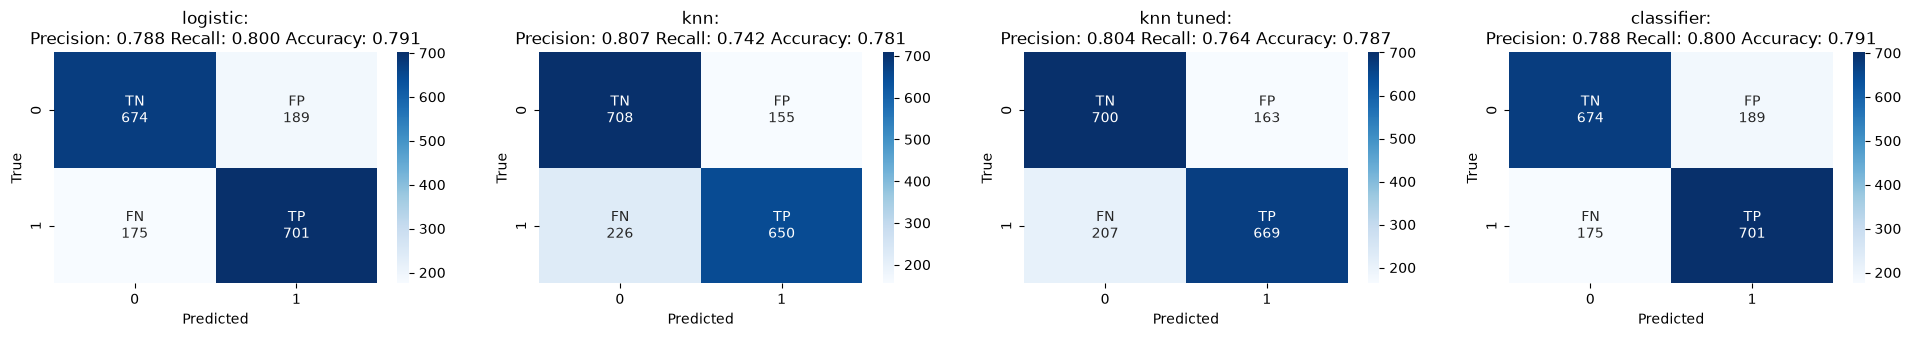

In [322]:
def plot_confusion_matrix(y_true, y_pred, ax, label):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    annotations = np.array([[f'TN\n{cm[0, 0]}', f'FP\n{cm[0, 1]}'],
                            [f'FN\n{cm[1, 0]}', f'TP\n{cm[1, 1]}']])
    sns.heatmap(cm, annot=annotations, fmt='', cmap='Blues', ax=ax)
    precision_large, recall_large, accuracy_large = precision_score(y_true, y_pred), recall_score(y_true, y_pred), accuracy_score(y_true, y_pred)
    ax.set_title(f"""{label}:
    Precision: {precision_large:.3f} Recall: {recall_large:.3f} Accuracy: {accuracy_large:.3f}""")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')

fig, ax = plt.subplots(1, 4, figsize=(24, 3))
plot_confusion_matrix(y_test, y_pred_lr, ax[0], "logistic")
plot_confusion_matrix(y_test, y_pred_knn, ax[1], "knn")
plot_confusion_matrix(y_test, y_pred_knn_tuned, ax[2], "knn tuned")
plot_confusion_matrix(y_test, y_pred_classifier, ax[3], "classifier")

In [323]:
pd.DataFrame({
    'probability': model_lr.predict_proba(X_test)[:, 1],
    'prediction': model_lr.predict(X_test)
})

,probability,prediction
0,0.921991,True
1,0.797069,True
2,0.083314,False
3,0.695885,True
4,0.161861,False
...,...,...
1734,0.882715,True
1735,0.100093,False
1736,0.770752,True
1737,0.276815,False


### Prepare submission

In [324]:
df_new = pd.read_csv('test.csv')
df_new = prep_data_for_sub(df_new)
df_new['Transported'] = classifier_model.predict(df_new)
df_new[['PassengerId', 'Transported']].to_csv('submission_20261109_02.csv', index=False)

ValueError: columns are missing: {'CabinSide', 'CabinDeck', 'CabinNumber'}